# 2.2 Paw × wheel cross-correlation QC (paper sessions)

The Lightning Pose timing/tracking check the neuromodulator collaborators run (davcrom/ibl_neuromodulators,
`per_third_crosscorr`; their pose-QC filter keeps sessions with **min peak ≥ 0.5**), applied to the 260 sessions
in the LDA (`tp_data.load_lda()`), for both cameras.

Per session and camera: paw speed (paw_l + paw_r displacement, likelihood ≥ 0.9) against |wheel velocity| on a
100 Hz grid, normalized cross-correlation in each third of the session, lags ±5 s. `peak_val` = maximum,
`peak_lag` = its lag (> 0: paw leads), `drift` = late − early lag.

Computed by `paw_wheel_xcorr.py` → `data_query/paw_wheel_xcorr.csv` (LP files deleted after use).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

sys.path.insert(0, '../GLM-HMM/transition_prediction')
sys.path.insert(0, '../../representation_learning/dopamine')
import tp_data as td
import da_data

THIRDS = ['early', 'mid', 'late']
THRESH = 0.5
d = pd.read_csv('data_query/paw_wheel_xcorr.csv')
d['min_peak'] = d[[f'peak_val_{t}' for t in THIRDS]].min(axis=1)
d['max_abs_lag'] = d[[f'peak_lag_{t}' for t in THIRDS]].abs().max(axis=1)
lda = td.load_lda()
d = d.merge(lda, left_on='eid', right_on='session', how='left')
print(d.groupby('camera').size(), '| errors:', d.filter(like='error').notna().sum().sum())

camera
left     260
right    260
dtype: int64 | errors: 0.0


## 1. Distributions per camera, against the NM sessions

,median_min_peak,n_below,frac_below,n_lag_over_50ms
left,0.622,37,0.142,14.0
right,0.559,72,0.277,17.0
NM sheet (all),0.645,51,0.237,NaN
NM_pose_qc_eids (kept),0.643,0,0.000,NaN


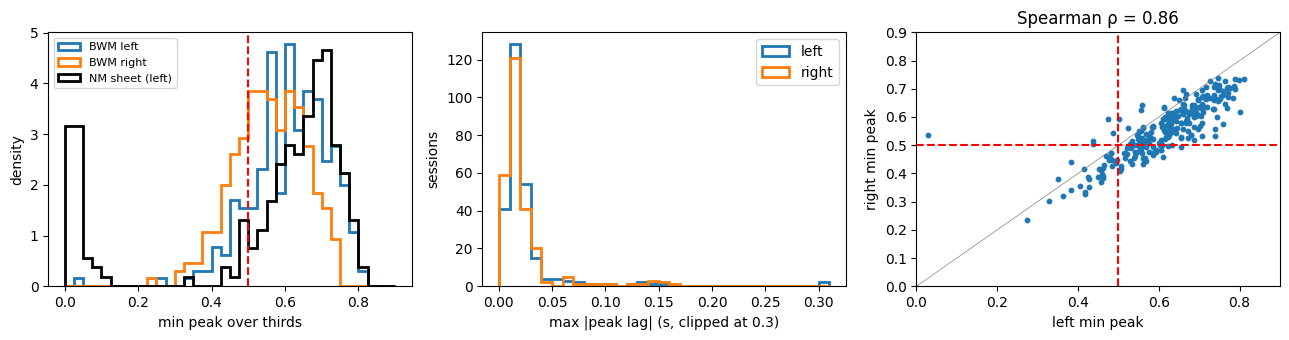

In [2]:
sheet = da_data.load_lp_sheet()
nm = pd.read_csv('../../neuromodulators/NM_pose_qc_eids.csv')
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bins = np.linspace(0, 0.9, 37)
for cam, c in [('left', 'C0'), ('right', 'C1')]:
    ax[0].hist(d.loc[d.camera == cam, 'min_peak'], bins, histtype='step', lw=2, color=c, density=True, label=f'BWM {cam}')
ax[0].hist(sheet['min_peak_val'].dropna(), bins, histtype='step', lw=2, color='k', density=True, label='NM sheet (left)')
ax[0].axvline(THRESH, ls='--', c='r')
ax[0].set(xlabel='min peak over thirds', ylabel='density'); ax[0].legend(fontsize=8)
for cam, c in [('left', 'C0'), ('right', 'C1')]:
    ax[1].hist(d.loc[d.camera == cam, 'max_abs_lag'].clip(upper=0.3), np.arange(0, 0.32, 0.01), histtype='step', lw=2, color=c, label=cam)
ax[1].set(xlabel='max |peak lag| (s, clipped at 0.3)', ylabel='sessions'); ax[1].legend()
w = d.pivot(index='eid', columns='camera', values='min_peak')
ax[2].scatter(w['left'], w['right'], s=10)
ax[2].plot([0, 1], [0, 1], c='gray', lw=.5); ax[2].axvline(THRESH, ls='--', c='r'); ax[2].axhline(THRESH, ls='--', c='r')
ax[2].set(xlabel='left min peak', ylabel='right min peak', xlim=(0, .9), ylim=(0, .9),
          title=f"Spearman ρ = {spearmanr(w['left'], w['right'])[0]:.2f}")
plt.tight_layout()

summ = d.groupby('camera').agg(median_min_peak=('min_peak', 'median'), n_below=('min_peak', lambda x: (x < THRESH).sum()),
                               frac_below=('min_peak', lambda x: (x < THRESH).mean()),
                               n_lag_over_50ms=('max_abs_lag', lambda x: (x > 0.05).sum()))
nm_ref = pd.DataFrame({'median_min_peak': [sheet['min_peak_val'].median(), nm['min_peak_corr'].median()],
                       'n_below': [(sheet['min_peak_val'] < THRESH).sum(), (nm['min_peak_corr'] < THRESH).sum()],
                       'frac_below': [(sheet['min_peak_val'] < THRESH).sum() / sheet['min_peak_val'].notna().sum(),
                                      (nm['min_peak_corr'] < THRESH).mean()]},
                      index=['NM sheet (all)', 'NM_pose_qc_eids (kept)'])
pd.concat([summ, nm_ref]).round(3)

## 2. Frame rates: camera labels

The right camera normally runs at 150 Hz and the left at 60 Hz. Sessions where this is reversed, or where the
right camera runs at ~260 Hz, are listed. Paw speed is in pixels/frame, so at 150 Hz the frame-to-frame
displacement is smaller and noisier, which by itself lowers the correlation with the wheel; the left-right gap
in §1 is expected for that reason.

In [3]:
fr = d.pivot(index='eid', columns='camera', values='frame_rate').round(0)
odd = fr[(fr['left'] > 100) | (fr['right'] < 100) | (fr['right'] > 200)]
odd.join(lda.set_index('session')[['mouse_name', 'lab']])

,left,right,mouse_name,lab
eid,,,,
19b44992-d527-4a12-8bda-aa11379cb08c,61.0,261.0,UCLA034,churchlandlab_ucla
21d21fc3-4201-4edc-802a-c67b61952548,149.0,60.0,NYU-37,angelakilab
3537d970-f515-4786-853f-23de525e110f,61.0,261.0,UCLA034,churchlandlab_ucla
7af49c00-63dd-4fed-b2e0-1b3bd945b20b,149.0,60.0,NYU-37,angelakilab
83d85891-bd75-4557-91b4-1cbb5f8bfc9d,149.0,60.0,NYU-37,angelakilab
8a3a0197-b40a-449f-be55-c00b23253bbf,61.0,261.0,UCLA034,churchlandlab_ucla
aec5d3cc-4bb2-4349-80a9-0395b76f04e2,149.0,60.0,NYU-37,angelakilab
ebc9392c-1ecb-4b4b-a545-4e3d70d23611,61.0,261.0,UCLA034,churchlandlab_ucla
f88d4dd4-ccd7-400e-9035-fa00be3bcfa8,149.0,60.0,NYU-37,angelakilab


## 3. Sessions below the threshold

In [4]:
cols = ['mouse_name', 'lab'] + [f'peak_val_{t}' for t in THIRDS] + ['max_abs_lag', 'drift']
flag = d[d['min_peak'] < THRESH].pivot(index='eid', columns='camera', values='min_peak')
flag = flag.join(lda.set_index('session')[['mouse_name', 'lab']])
flag['both'] = (flag[['left', 'right']] < THRESH).all(axis=1)
print(f"{len(flag)} sessions below {THRESH} in at least one camera, {flag['both'].sum()} in both")
flag.sort_values(['both', 'left']).round(2)

77 sessions below 0.5 in at least one camera, 32 in both


,left,right,mouse_name,lab,both
eid,,,,,
6c6983ef-7383-4989-9183-32b1a300d17a,0.03,NaN,SWC_054,mrsicflogel,False
f88d4dd4-ccd7-400e-9035-fa00be3bcfa8,0.44,NaN,NYU-37,angelakilab,False
83d85891-bd75-4557-91b4-1cbb5f8bfc9d,0.44,NaN,NYU-37,angelakilab,False
6f09ba7e-e3ce-44b0-932b-c003fb44fb89,0.47,NaN,SWC_043,mrsicflogel,False
6668c4a0-70a4-4012-a7da-709660971d7a,0.49,NaN,DY_009,danlab,False
...,...,...,...,...,...
7bee9f09-a238-42cf-b499-f51f765c6ded,0.48,0.47,DY_011,danlab,True
e012d3e3-fdbc-4661-9ffa-5fa284e4e706,0.48,0.42,DY_020,danlab,True
c16d3557-b2c1-4545-93d0-112ac0915d93,0.48,0.45,PL030,hausserlab,True


In [5]:
by_lab = d.assign(below=d['min_peak'] < THRESH).groupby(['lab', 'camera'])['below'].mean().unstack().round(2)
by_lab['n_sessions'] = lda.groupby('lab').size()
by_lab

camera,left,right,n_sessions
lab,,,
angelakilab,0.32,0.77,31
churchlandlab,0.03,0.20,30
churchlandlab_ucla,0.12,0.41,17
danlab,0.28,0.46,39
hausserlab,0.12,0.17,41
mainenlab,0.15,0.22,27
mrsicflogel,0.06,0.03,34
steinmetzlab,0.13,0.13,15
wittenlab,0.00,0.06,17


Where peak drops in a single third (one-third failures: tracking or timing breaks partway through):

In [6]:
third = d[[f'peak_val_{t}' for t in THIRDS]]
single = d[(d['min_peak'] < 0.4) & (third.max(axis=1) > 0.6)]
single[['eid', 'camera', 'mouse_name'] + [f'peak_val_{t}' for t in THIRDS] + [f'peak_lag_{t}' for t in THIRDS]].round(2)

,eid,camera,mouse_name,peak_val_early,peak_val_mid,peak_val_late,peak_lag_early,peak_lag_mid,peak_lag_late
180,57b5ae8f-d446-4161-b439-b191c5e3e77b,left,CSHL059,0.71,0.70,0.38,0.01,0.01,0.01
181,57b5ae8f-d446-4161-b439-b191c5e3e77b,right,CSHL059,0.63,0.68,0.34,0.01,0.00,0.01
226,6c6983ef-7383-4989-9183-32b1a300d17a,left,SWC_054,0.64,0.67,0.03,-0.01,-0.02,1.43
313,91a3353a-2da1-420d-8c7c-fad2fedfdd18,right,NYU-39,0.40,0.60,0.76,0.03,0.03,0.02
333,9b528ad0-4599-4a55-9148-96cc1d93fb24,right,NR_0019,0.65,0.69,0.39,0.01,0.01,0.00
478,f25642c6-27a5-4a97-9ea0-06652db79fbd,left,DY_014,0.36,0.60,0.33,0.04,0.03,0.02


Timing: sessions with a peak lag beyond 100 ms in any third (a lag that is the same in both cameras points to
the wheel/trial clock or shared camera sync; one camera only, to that camera's timestamps):

In [7]:
d[d['max_abs_lag'] > 0.1][['eid', 'camera', 'mouse_name', 'lab'] + [f'peak_lag_{t}' for t in THIRDS] + ['min_peak']].round(2)

,eid,camera,mouse_name,lab,peak_lag_early,peak_lag_mid,peak_lag_late,min_peak
192,5c7d2345-1f0e-40e5-aad7-2c6133b71b09,left,SWC_054,mrsicflogel,-0.02,-0.02,0.14,0.55
193,5c7d2345-1f0e-40e5-aad7-2c6133b71b09,right,SWC_054,mrsicflogel,-0.01,-0.01,0.12,0.52
219,695a6073-eae0-49e0-bb0f-e9e57a9275b9,right,SWC_043,mrsicflogel,-0.01,0.02,0.16,0.61
226,6c6983ef-7383-4989-9183-32b1a300d17a,left,SWC_054,mrsicflogel,-0.01,-0.02,1.43,0.03
227,6c6983ef-7383-4989-9183-32b1a300d17a,right,SWC_054,mrsicflogel,-0.01,-0.01,0.15,0.54
288,875c1e5c-f7ec-45ac-ab82-ecfe7276a707,left,SWC_060,mrsicflogel,-0.01,0.00,-4.91,0.56
316,93ad879a-aa42-4150-83e1-38773c9785e4,left,NYU-48,angelakilab,0.12,0.13,0.12,0.61
317,93ad879a-aa42-4150-83e1-38773c9785e4,right,NYU-48,angelakilab,0.14,0.13,0.13,0.50
350,a405053a-eb13-4aa4-850c-5a337e5dc7fd,left,NYU-48,angelakilab,0.12,0.13,-0.01,0.60
351,a405053a-eb13-4aa4-850c-5a337e5dc7fd,right,NYU-48,angelakilab,0.13,0.13,-0.04,0.51


## 4. Is QC related to LD1?

left, lab-centred: rho = -0.17, p = 0.0071
right, lab-centred: rho = -0.26, p = 2.1e-05


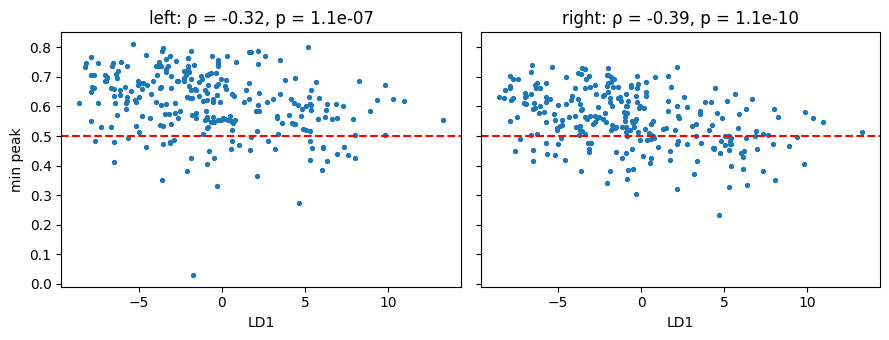

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for a, cam in zip(ax, ['left', 'right']):
    x = d[d.camera == cam]
    a.scatter(x['lda_1'], x['min_peak'], s=8)
    a.axhline(THRESH, ls='--', c='r')
    r, p = spearmanr(x['lda_1'], x['min_peak'])
    a.set(title=f'{cam}: ρ = {r:.2f}, p = {p:.2g}', xlabel='LD1')
ax[0].set_ylabel('min peak')
plt.tight_layout()
centre = lambda x, c: x[c] - x.groupby('lab')[c].transform('mean')
for cam in ['left', 'right']:
    x = d[d.camera == cam]
    r, p = spearmanr(centre(x, 'lda_1'), centre(x, 'min_peak'))
    print(f'{cam}, lab-centred: rho = {r:.2f}, p = {p:.2g}')

## Summary

- **No failures to load**: all 260 sessions have LP for both cameras, tracked in > 98 % of frames.
- **Peak values are in the NM range.** Left camera median min peak 0.62 (NM sheet 0.645); right 0.56. The right camera
  is lower in every lab because it runs at 150 Hz (paw speed in pixels/frame is smaller and noisier), so the 0.5
  threshold, calibrated on 60 Hz left-camera NM data, is too strict for it.
- **Below 0.5**: 37 sessions left, 72 right, 77 in either, 32 in both. Most sit just under 0.5 with all three thirds
  low and lag ≈ 0: weaker paw–wheel coupling across the session, not a tracking or timing break.
- **Camera labels**: NYU-37 (angelakilab) has left = 150 Hz / right = 60 Hz in all 5 sessions, i.e. the camera
  labels are swapped relative to every other lab (consistent with the mirrored paw naming noted before). UCLA034's
  right camera runs at ~260 Hz. angelakilab's right-camera failure rate (77 %) is the largest lab effect.
- **Real breaks** (one third collapses or the lag jumps):
  - SWC_054 `6c6983ef` left camera: late third peak 0.03 at lag 1.4 s (left timestamps break; right is fine).
  - CSHL059 `57b5ae8f`, NR_0019 `9b528ad0`, DY_014 `f25642c6`: late (or early) third drops to ~0.35.
  - NYU-48 (3 sessions): a constant ~130 ms paw-lags-wheel offset in both cameras that disappears partway through,
    so a shared clock problem (wheel/trials or camera sync), not one camera.
  - SWC_060 `875c1e5c` left: late-third peak at −4.9 s (edge of the window); ibl_witten_29 right: constant −120 ms.
- **QC is not independent of LD1**: min peak falls with LD1 (ρ ≈ −0.32 left, −0.39 right; lab-centred −0.17 / −0.26).
  So excluding by a peak threshold would remove sessions non-randomly along LD1 — and low coupling may itself be
  behaviour (paw moving without the wheel), not bad data. Exclude only the clear breaks above, not by threshold.
